29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7919 - loss: 0.6035 - val_accuracy: 0.8437 - val_loss: 0.4342
Epoch 2/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8498 - loss: 0.4230 - val_accuracy: 0.8638 - val_loss: 0.3822
Epoch 3/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8635 - loss: 0.3832 - val_accuracy: 0.8703 - val_loss: 0.3541
Test accuracy: 86.61%
Test loss: 0.3746


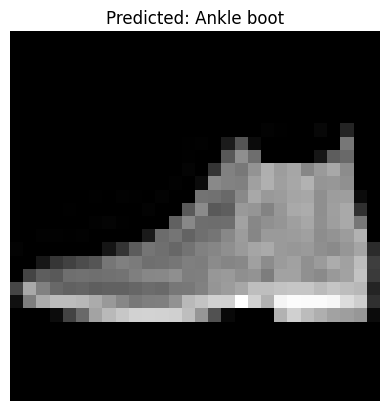

Predicted: Ankle boot
Actual: Ankle boot


In [1]:

# Deep Learning Project: Fashion-MNIST Classification

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the dataset
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

# 2. Normalize image pixels
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# 3. Define clothing categories
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# 4. Build a neural network
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10, activation="softmax")
])

# 5. Configure the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 6. Train the model
model.fit(
    X_train, y_train,
    epochs=3,
    batch_size=128,
    validation_split=0.1
)

# 7. Evaluate on test data
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Test loss: {test_loss:.4f}")

# 8. Show an example prediction
index = 0
prediction = model.predict(
    X_test[index:index+1], verbose=0
)[0]

predicted_class = int(np.argmax(prediction))

plt.imshow(X_test[index], cmap="gray")
plt.title(f"Predicted: {class_names[predicted_class]}")
plt.axis("off")
plt.show()

print("Predicted:", class_names[predicted_class])
print("Actual:", class_names[int(y_test[index])])
